In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import math
import copy

In [4]:
image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

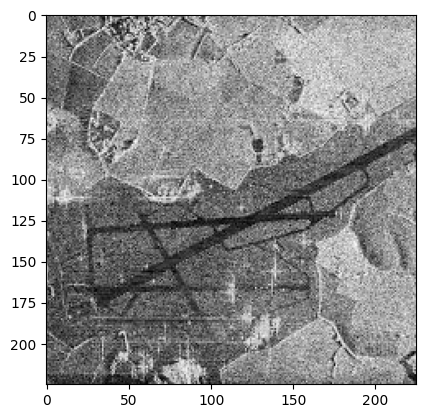

In [5]:
plt.imshow(image_gray, cmap='gray')

**1. Найти наиболее протяжённый участок**

(np.float64(-0.5), np.float64(224.5), np.float64(224.5), np.float64(-0.5))

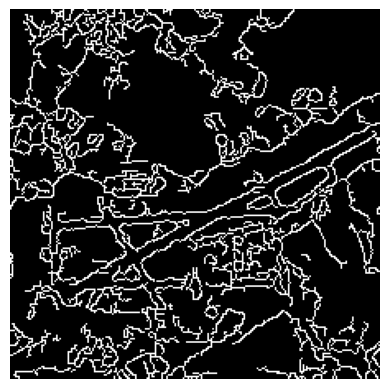

In [6]:
image_filtered = cv2.medianBlur(image_gray, 5)
canny = cv2.Canny(image_filtered, 50, 150,apertureSize = 3)

plt.imshow(canny, cmap='gray')
plt.axis('off')

In [7]:
lines = cv2.HoughLinesP(canny, 1, np.pi / 180, 40, minLineLength=100, maxLineGap=10)
image_lines = image.copy()

longest = None
max_length = 0

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line
        cv2.line(image_lines, (x1, y1), (x2, y2), (0, 255, 0), 2, cv2.LINE_AA)
        length = math.hypot(x2 - x1, y2 - y1)
        if length > max_length:
            max_length = length
            longest = (x1, y1, x2, y2)

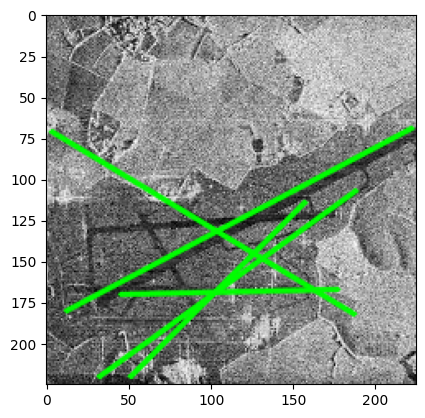

In [8]:
plt.imshow(image_lines)

**выбор самой длинной**

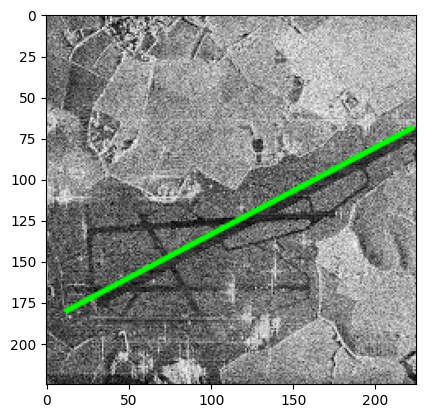

In [9]:
image_longest = image.copy()
if longest is not None:
    x1, y1, x2, y2 = longest
    cv2.line(image_longest, (x1, y1), (x2, y2), (0, 255, 0), 2, cv2.LINE_AA)

plt.imshow(image_longest)

**2. провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.**

**Точечная бинаризация**

(np.float64(-0.5), np.float64(224.5), np.float64(224.5), np.float64(-0.5))

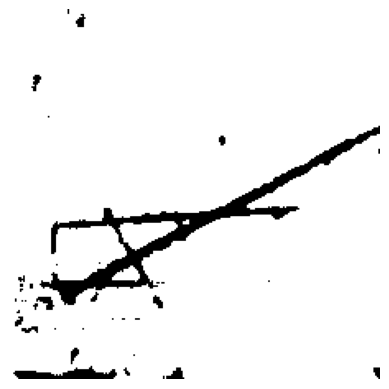

In [10]:
T = 70
bin_img = copy.deepcopy(image_filtered)
bin_img[image_filtered < T] = 0
bin_img[image_filtered >= T] = 255
plt.imshow(bin_img, cmap='gray')
plt.axis('off')

**Бинаризация Отсу**

Порог Отсу: 128.0


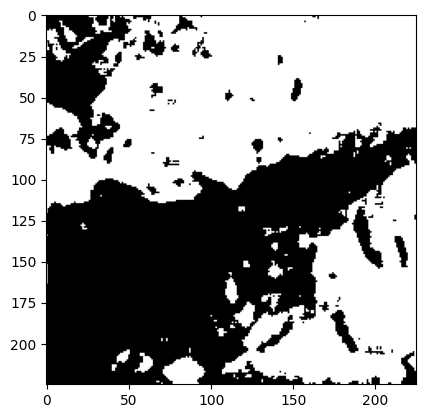

In [11]:
otsu_threshold, th2 = cv2.threshold(image_filtered, 0, 255,
                                    cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f'Порог Отсу: {otsu_threshold}')
plt.imshow(th2, cmap='gray')

**Адаптивная бинаризация**

(np.float64(-0.5), np.float64(224.5), np.float64(224.5), np.float64(-0.5))

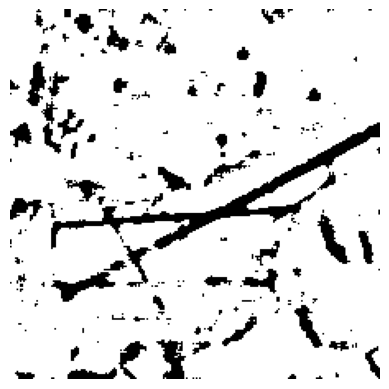

In [12]:
th3 = cv2.adaptiveThreshold(image_filtered, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                            cv2.THRESH_BINARY, 71, 21)

plt.imshow(th3, cmap='gray')
plt.axis('off')

**Сравнение трёх методов**

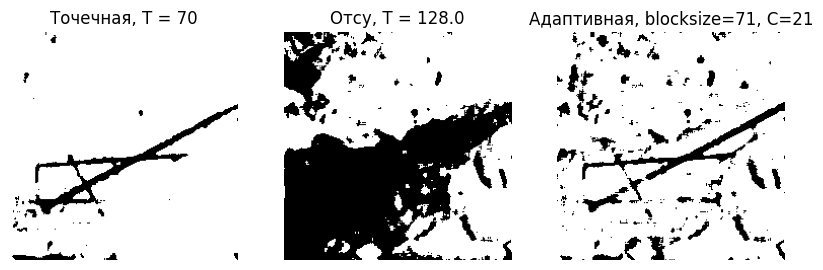

In [13]:
images = [bin_img, th2, th3]
titles = ['Точечная, T = 70', f'Отсу, T = {otsu_threshold}', 'Адаптивная, blocksize=71, C=21']

plt.figure(figsize=(10, 4))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')